In [1]:
!nvidia-smi
!pip install -q ultralytics
import ultralytics; ultralytics.checks()

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 0.1/112.6 GB disk)


In [5]:
from google.colab import drive
drive.mount('/content/drive')

ZIP_PATH = '/content/drive/MyDrive/YOLO.v1i.yolov8.zip'
!rm -rf /content/dataset && mkdir -p /content/dataset
!unzip -q "{ZIP_PATH}" -d /content/dataset
!ls /content/dataset

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
replace /content/dataset/data.yaml? [y]es, [n]o, [A]ll, [N]one, [r]ename: A
data.yaml  README.dataset.txt  README.roboflow.txt  test  train  valid


In [6]:
import zipfile, collections
z = zipfile.ZipFile(ZIP_PATH)
c = collections.Counter(z.namelist())
dups = [n for n, k in c.items() if k > 1]
print(f'전체 {len(z.namelist())}개 항목 / 중복된 이름 {len(dups)}개')
print(dups[:5])

전체 813개 항목 / 중복된 이름 1개
['data.yaml']


In [7]:
import yaml
from pathlib import Path

DS = Path('/content/dataset')
yaml_path = next(DS.rglob('data.yaml'))
DS = yaml_path.parent
d = yaml.safe_load(open(yaml_path))

d['path'] = str(DS)
d['train'] = 'train/images'
d['val'] = 'valid/images'
d['test'] = 'test/images'
yaml.safe_dump(d, open(yaml_path, 'w'), allow_unicode=True)

DATA = str(yaml_path)
print('data.yaml:', DATA)
print('클래스:', d['names'], '/ nc =', d.get('nc'))

data.yaml: /content/dataset/data.yaml
클래스: ['mouse', 'pencil_case', 'tumbler'] / nc = 3


In [8]:
from collections import Counter

names = d['names'] if isinstance(d['names'], list) else list(d['names'].values())
for split in ['train', 'valid', 'test']:
    img_dir = DS / split / 'images'
    lbl_dir = DS / split / 'labels'
    if not img_dir.exists():
        print(f'[{split}] 폴더 없음'); continue
    imgs = list(img_dir.glob('*'))
    cnt, empty = Counter(), 0
    for l in lbl_dir.glob('*.txt'):
        lines = [x for x in l.read_text().splitlines() if x.strip()]
        if not lines: empty += 1
        for x in lines:
            cnt[names[int(x.split()[0])]] += 1
    print(f'[{split}] 이미지 {len(imgs)}장 | 라벨 없는 파일 {empty}개 | 박스 수 {dict(cnt)}')

[train] 이미지 283장 | 라벨 없는 파일 0개 | 박스 수 {'pencil_case': 141, 'mouse': 89, 'tumbler': 284}
[valid] 이미지 81장 | 라벨 없는 파일 0개 | 박스 수 {'mouse': 32, 'pencil_case': 53, 'tumbler': 39}
[test] 이미지 40장 | 라벨 없는 파일 0개 | 박스 수 {'mouse': 19, 'tumbler': 21, 'pencil_case': 5}


In [9]:
from ultralytics import YOLO

MODEL = 'yolov8n.pt'                           # 비교용: 'yolov8s.pt'
RUN_NAME = 'yolov8n_3cls'
PROJECT = '/content/drive/MyDrive/yolo_runs'

model = YOLO(MODEL)
results = model.train(
    data=DATA,
    epochs=50,
    imgsz=640,
    batch=16,
    patience=15,
    seed=0,
    workers=2,
    project=PROJECT,
    name=RUN_NAME,
    exist_ok=True,
)

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n_3cls, nbs=64, nms=None, opset=None, optimize=False, opt

저장된 파일: ['BoxF1_curve.png', 'BoxPR_curve.png', 'BoxP_curve.png', 'BoxR_curve.png', 'args.yaml', 'confusion_matrix.png', 'confusion_matrix_normalized.png', 'labels.jpg', 'results.csv', 'results.png', 'train_batch0.jpg', 'train_batch1.jpg', 'train_batch2.jpg', 'train_batch720.jpg', 'train_batch721.jpg', 'train_batch722.jpg', 'val_batch0_labels.jpg', 'val_batch0_pred.jpg', 'val_batch1_labels.jpg', 'val_batch1_pred.jpg', 'val_batch2_labels.jpg', 'val_batch2_pred.jpg', 'weights']
results.png


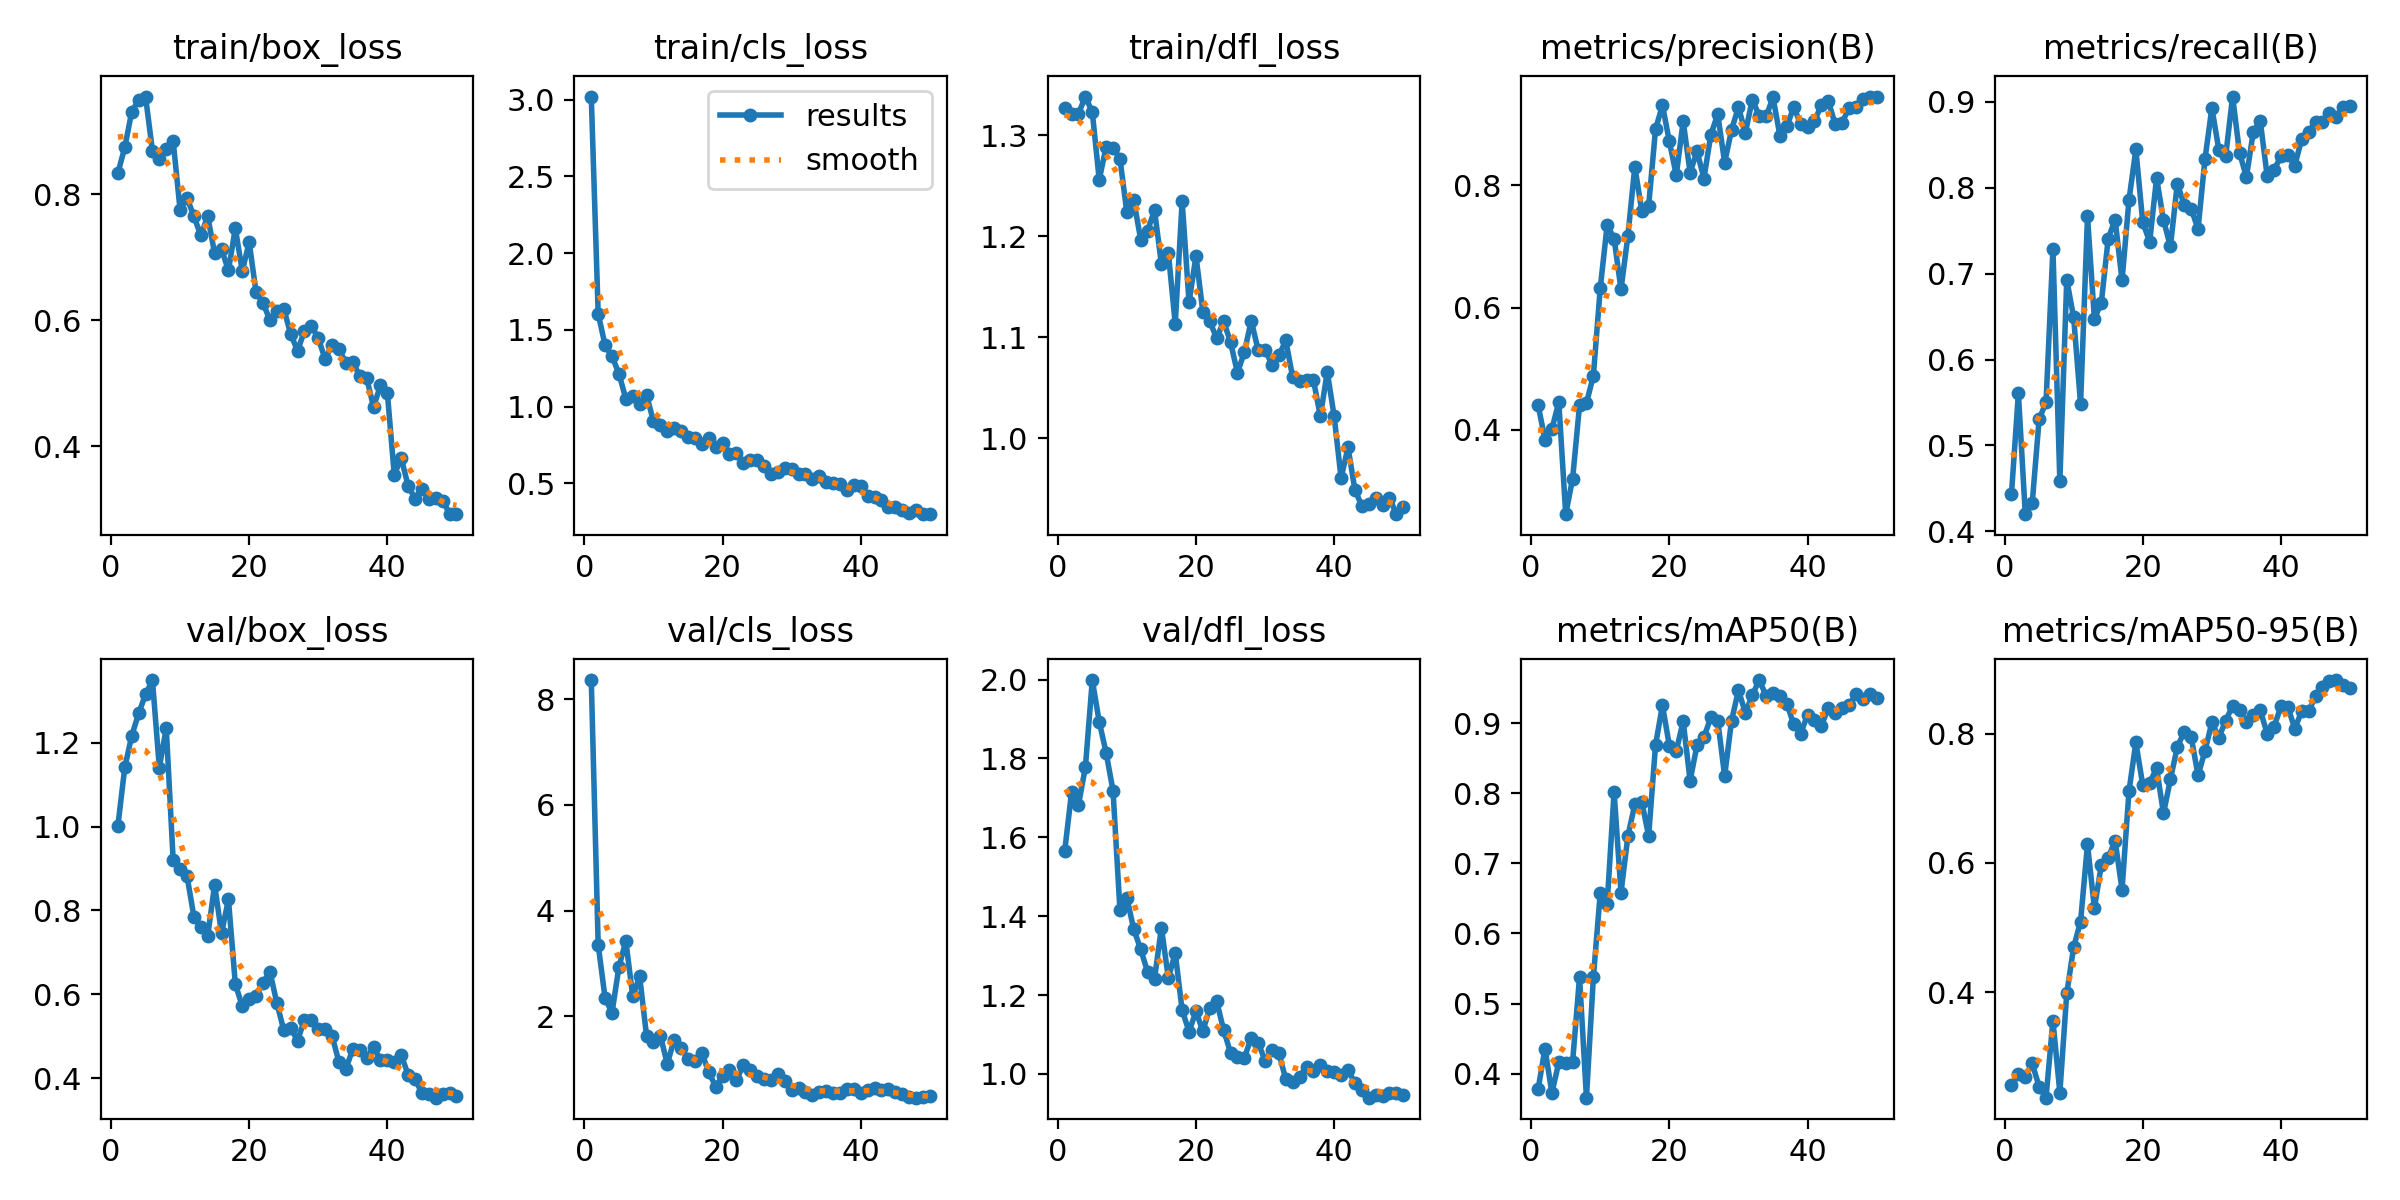

confusion_matrix_normalized.png


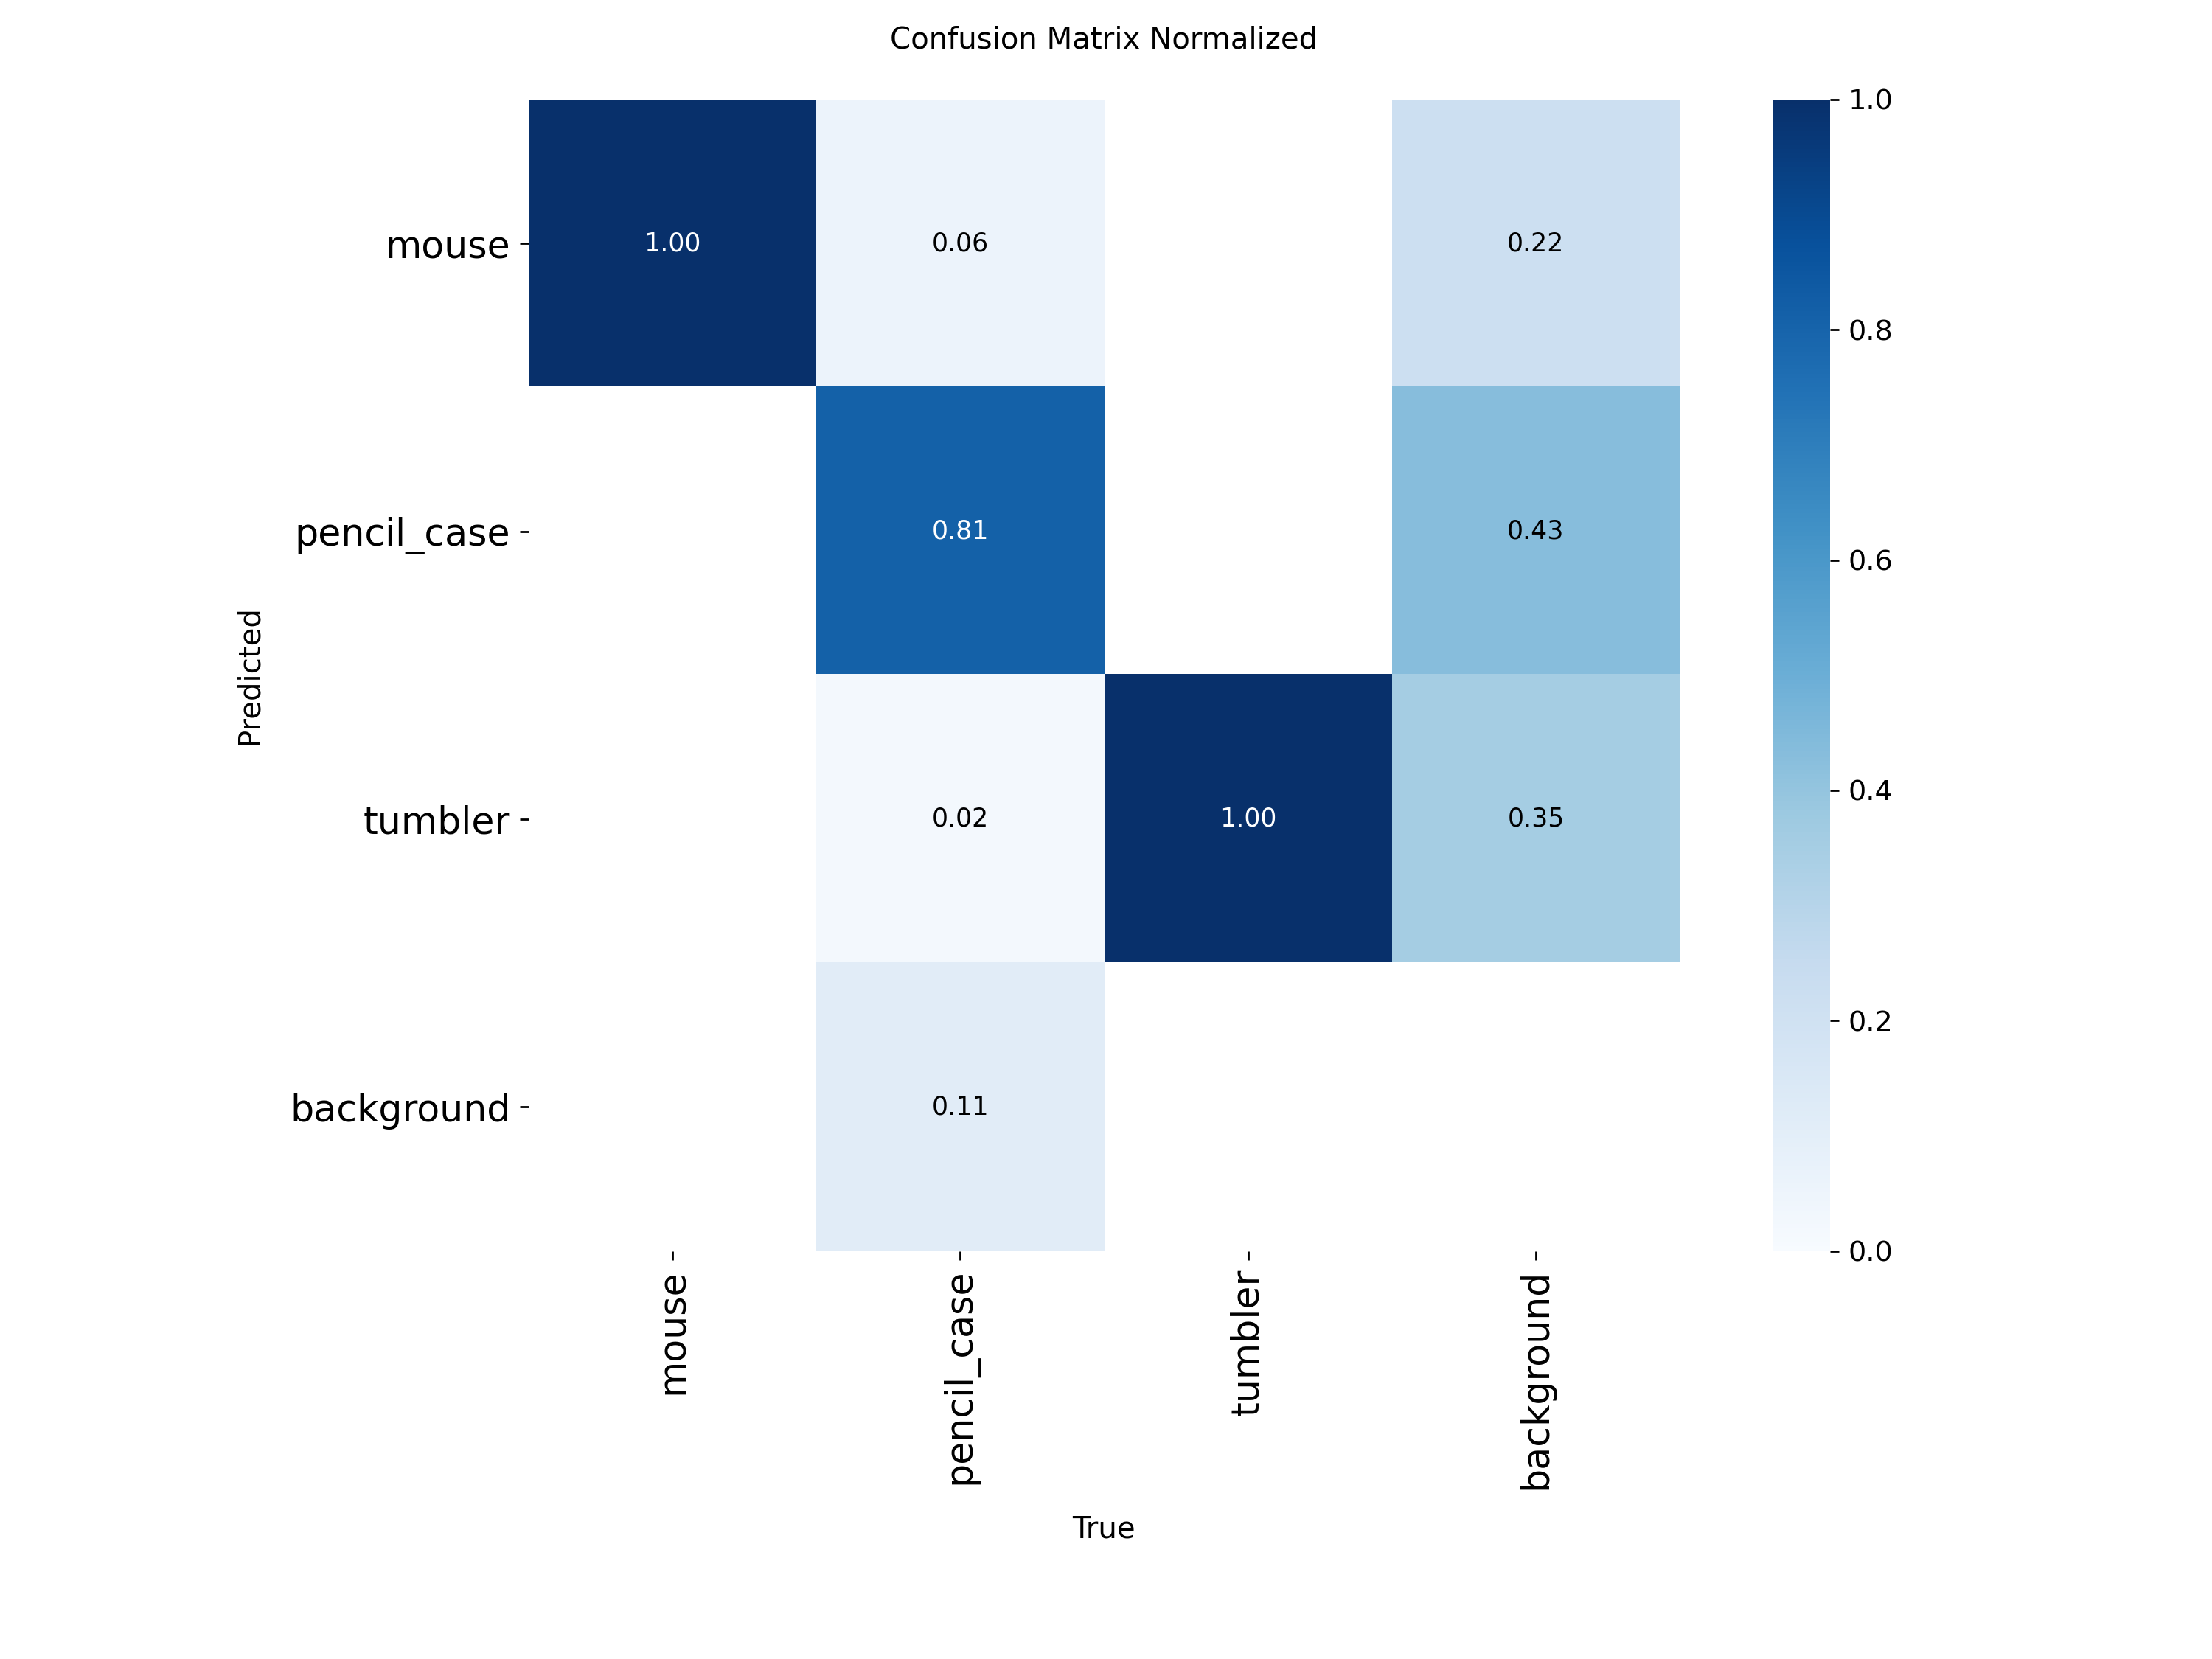

BoxPR_curve.png


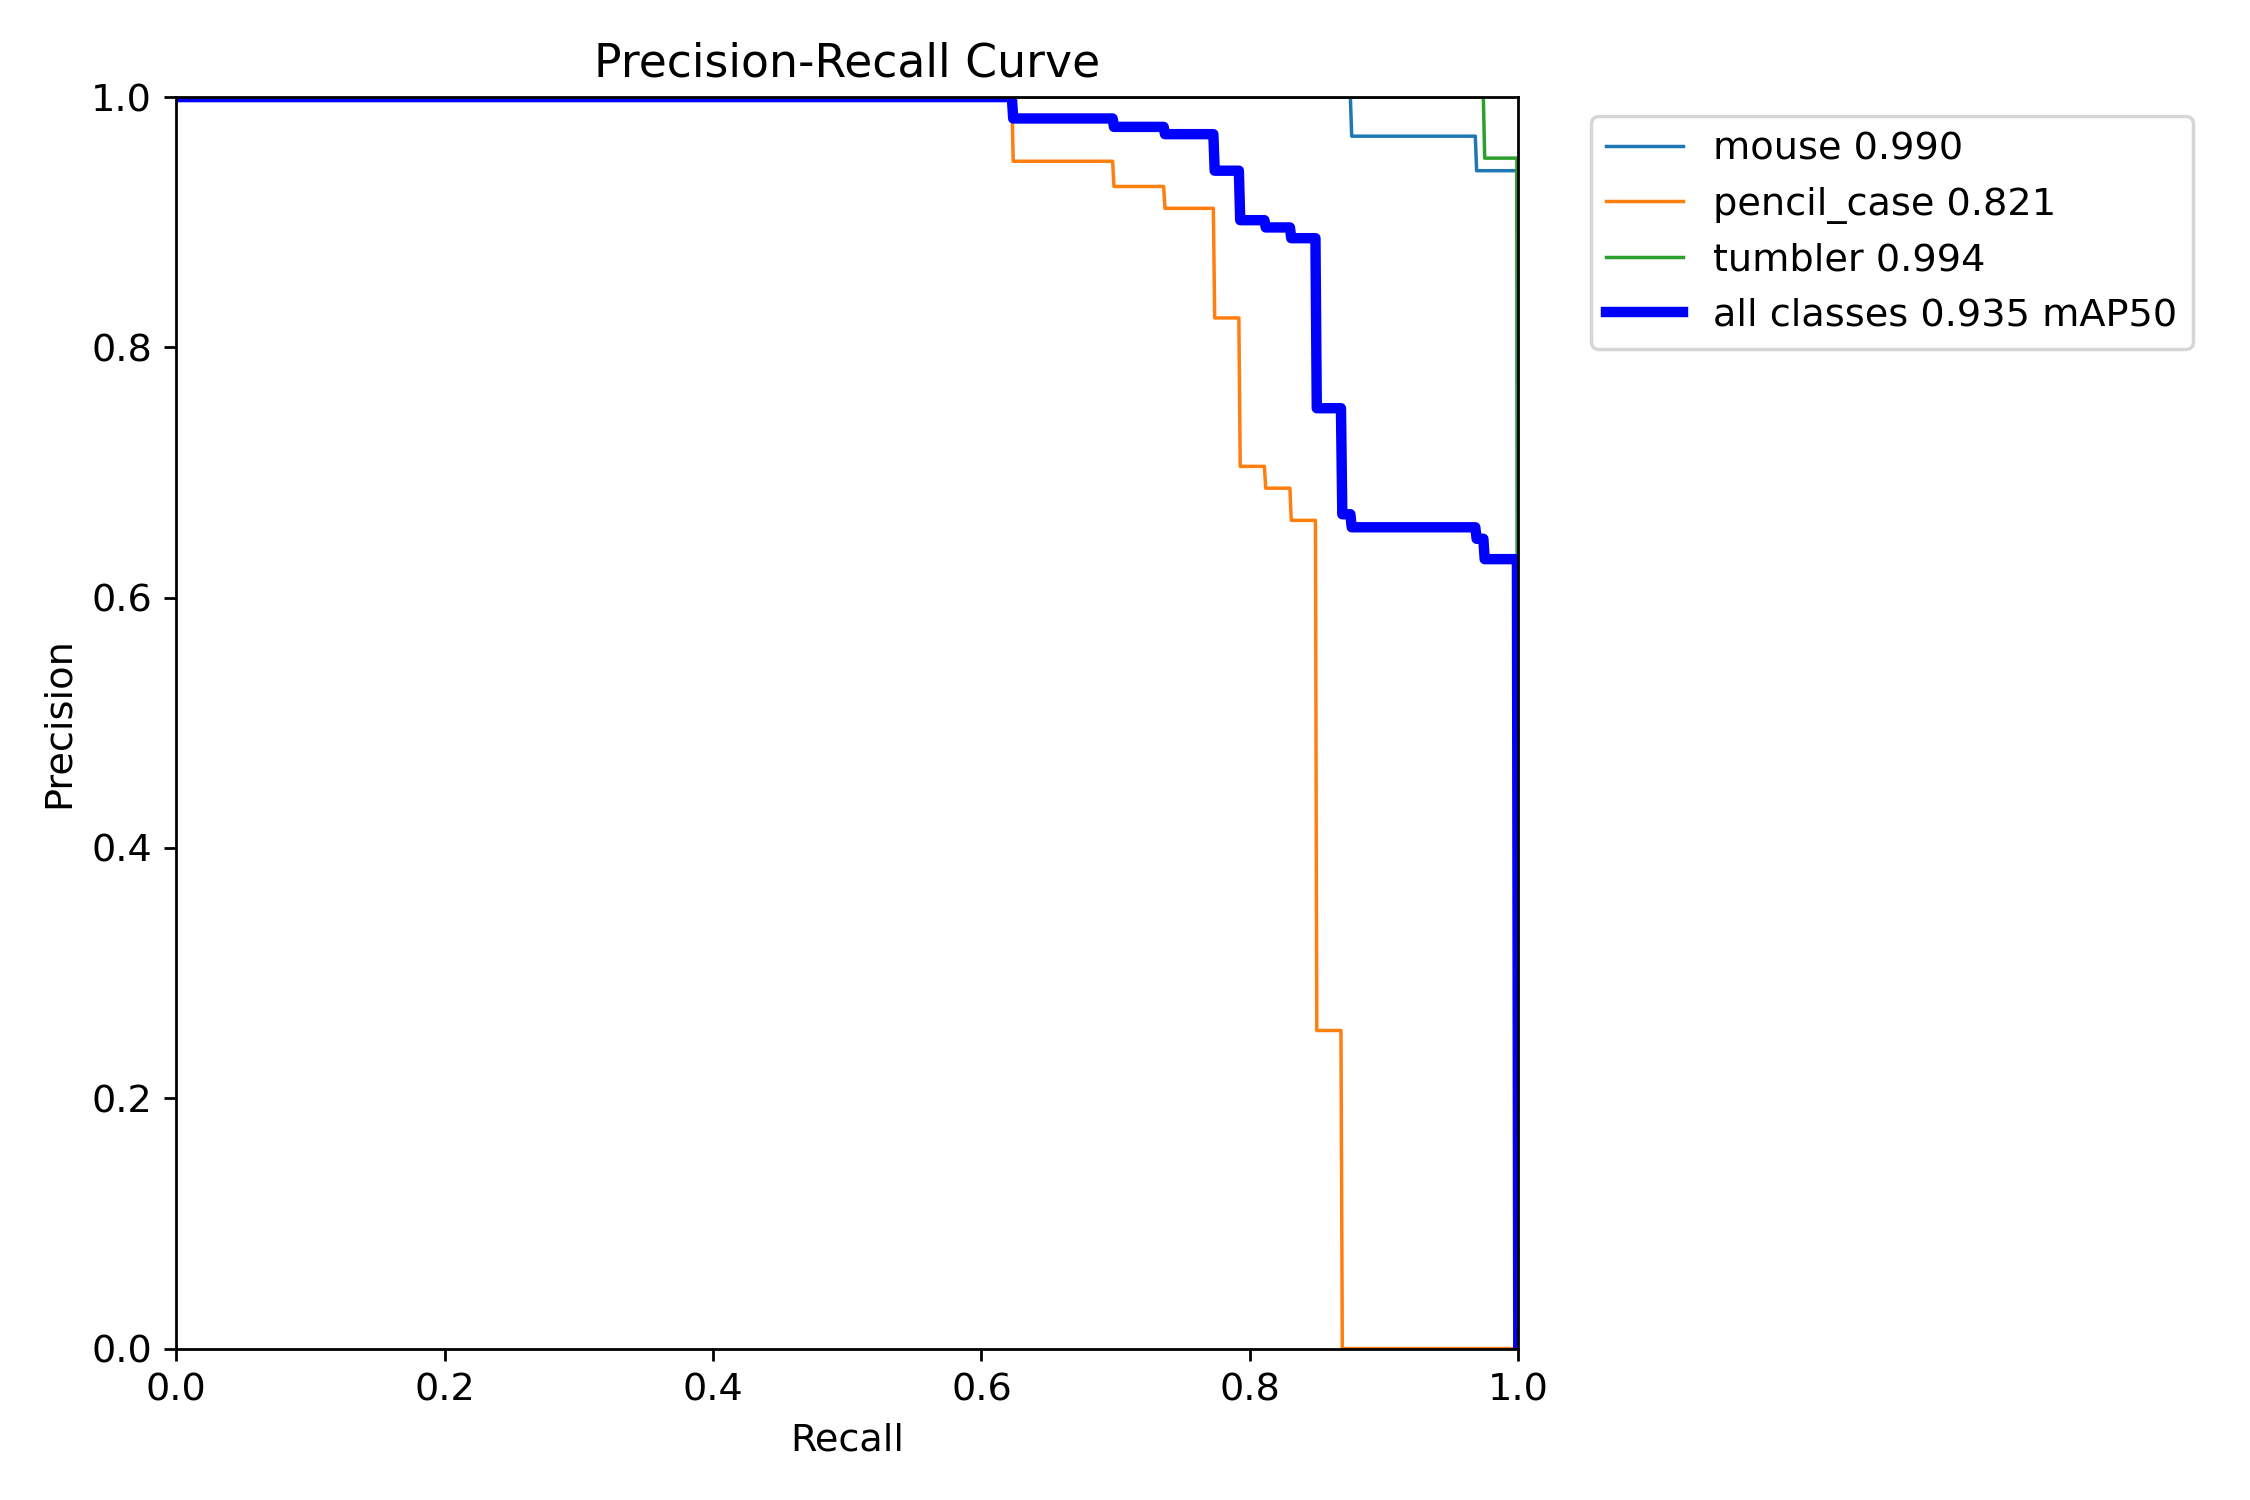

In [12]:
from IPython.display import Image, display
import os

RUN = f'{PROJECT}/{RUN_NAME}'
print('저장된 파일:', sorted(os.listdir(RUN)))

for f in ['results.png', 'confusion_matrix_normalized.png', 'BoxPR_curve.png', 'PR_curve.png']:
    path = f'{RUN}/{f}'
    if os.path.exists(path):
        print(f)
        display(Image(path, width=800))

In [13]:
best = YOLO(f'{RUN}/weights/best.pt')
print('===== valid =====')
best.val(data=DATA, split='val')
print('===== test =====')
best.val(data=DATA, split='test')

===== valid =====
Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 825.4±446.7 MB/s, size: 28.0 KB)
val: Scanning /content/dataset/valid/labels.cache... 81 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 81/81 24.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 2.7it/s 2.2s
                   all         81        124      0.948      0.889      0.943      0.884
                 mouse         22         32      0.994      0.875       0.99      0.901
           pencil_case         31         53      0.926      0.792      0.845      0.766
               tumbler         28         39      0.924          1      0.994      0.985
Speed: 2.8ms preprocess, 6.1ms inference, 0.0ms loss, 3.5ms postprocess per image
Results saved to /content/runs/detect/val
=

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7fca44550ec0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04

In [47]:
import glob, os

vids = []
for ext in ('mp4', 'mov', 'avi', 'mkv', 'webm', 'MP4', 'MOV'):
    vids += glob.glob(f'/content/drive/MyDrive/**/*.{ext}', recursive=True)
vids = [v for v in vids if '/yolo_runs/' not in v and '/yolo_submit/' not in v]
vids.sort(key=os.path.getmtime, reverse=True)

print('Drive에서 찾은 영상 (최근 순):')
for v in vids[:10]:
    print(' -', v)

VIDEO_PATH = vids[0]   # 가장 최근 영상. 다른 영상이면 위 목록에서 복사해 직접 지정
print('\n사용할 영상:', VIDEO_PATH)

Drive에서 찾은 영상 (최근 순):
 - /content/drive/MyDrive/데모영상.mp4

사용할 영상: /content/drive/MyDrive/데모영상.mp4


In [48]:
START = 1       # 몇 초부터 자를지
DURATION = 5    # 과제 요구: 5초 분량

!ffmpeg -y -loglevel error -ss {START} -t {DURATION} -i "{VIDEO_PATH}" -an -vf "scale='min(1280,iw)':-2" -c:v libx264 -pix_fmt yuv420p /content/clip.mp4
!ls -la /content/clip.mp4

-rw-r--r-- 1 root root 2269352 Nov 24 10:57 /content/clip.mp4


In [49]:
from ultralytics import YOLO
from collections import defaultdict

BEST_PT = '/content/drive/MyDrive/yolo_runs/yolov8n_3cls/weights/best.pt'
model = YOLO(BEST_PT)

results = model.track(
    source='/content/clip.mp4',
    persist=True,
    tracker='bytetrack.yaml',   # 또는 'botsort.yaml'
    conf=0.25,
    save=True,
    project='/content/runs_track',
    name='track',
    exist_ok=True,
    verbose=False,
)

names = model.names
frames = defaultdict(int)
ids = defaultdict(set)
for r in results:
    if r.boxes is None or len(r.boxes) == 0:
        continue
    cls = r.boxes.cls.int().tolist()
    tid = r.boxes.id.int().tolist() if r.boxes.id is not None else [None] * len(cls)
    for c, t in zip(cls, tid):
        frames[names[c]] += 1
        if t is not None:
            ids[names[c]].add(t)

print(f'총 {len(results)}프레임')
for n in names.values():
    print(f'{n}: 검출 {frames[n]}회 / 추적 ID {len(ids[n])}개 {sorted(ids[n])}')

WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

Results saved to /content/runs_track/track
총 150프레임
mouse: 검출 206회 / 추적 ID 6개 [1, 2, 3, 28, 31, 37]
pencil_case: 검출 89회 / 추적 ID 3개 [2, 18, 37]
tumbler: 검출 148회 / 추적 ID 2개 [1, 35]


In [50]:
import base64, shutil
from IPython.display import HTML

cands = glob.glob('/content/runs_track/track/*.avi') + glob.glob('/content/runs_track/track/*.mp4')
src = max(cands, key=os.path.getmtime)
print('결과 파일:', src)

!ffmpeg -y -loglevel error -i "{src}" -c:v libx264 -pix_fmt yuv420p /content/result.mp4

os.makedirs('/content/drive/MyDrive/yolo_submit', exist_ok=True)
shutil.copy('/content/result.mp4', '/content/drive/MyDrive/yolo_submit/tracking_result.mp4')

data = base64.b64encode(open('/content/result.mp4', 'rb').read()).decode()
HTML(f'<video width="480" controls src="data:video/mp4;base64,{data}"></video>')

Output hidden; open in https://colab.research.google.com to view.